# Ensamble

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error

In [2]:
# Generate synthetic data
np.random.seed(42)
X = np.sort(np.random.rand(30,1)*2-1,axis=0)
y = X**3+0.1*np.random.randn(30,1)

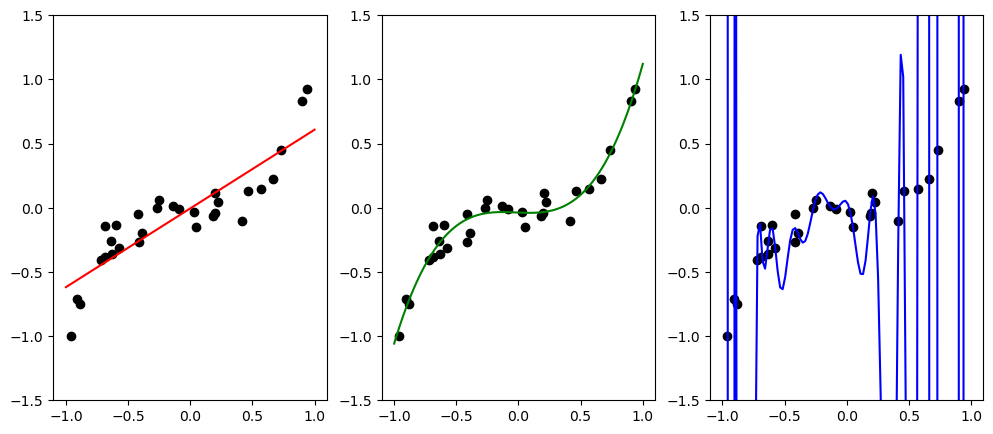

In [3]:
# Models
degree = [1,3,25]
colors = ['r','g','b']
plt.figure(figsize=(12,5))

for i, d in enumerate(degree):
    poly = PolynomialFeatures(degree=d)
    X_poly = poly.fit_transform(X)
    model = LinearRegression().fit(X_poly,y)
    X_plot = np.linspace(-1,1,100).reshape(-1,1)
    y_plot = model.predict(poly.transform(X_plot))
    
    
    plt.subplot(1, 3, i+1)
    plt.scatter(X, y, color='black', label='Data')
    plt.plot(X_plot, y_plot, color=colors[i], label=f'Degree{d}')
    plt.ylim(-1.5,1.5)
    plt.xlim(-1.1,1.1)

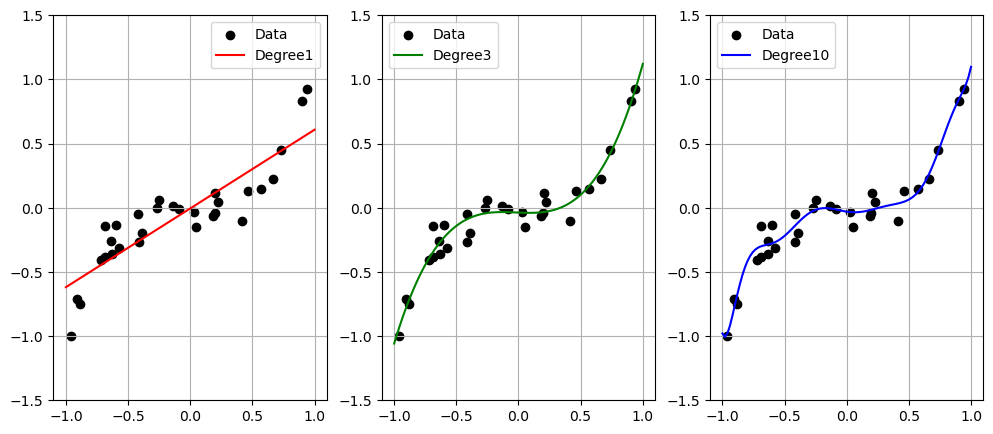

In [4]:
# Models
degree = [1,3,10]
colors = ['r','g','b']
plt.figure(figsize=(12,5))

for i, d in enumerate(degree):
    poly = PolynomialFeatures(degree=d)
    X_poly = poly.fit_transform(X)
    model = LinearRegression().fit(X_poly,y)
    X_plot = np.linspace(-1,1,100).reshape(-1,1)
    y_plot = model.predict(poly.transform(X_plot))
    
    plt.subplot(1, 3, i+1)
    plt.scatter(X, y, color='black', label='Data')
    plt.plot(X_plot, y_plot, color=colors[i], label=f'Degree{d}')
    plt.ylim(-1.5,1.5)
    plt.xlim(-1.1,1.1)
    plt.legend()
    plt.grid()

In [19]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import pandas as pd

In [6]:
# load and prepare the data
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target)

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.3,random_state=42)

In [8]:
sc = StandardScaler()
X_train_scaled = sc.fit_transform(X_train)
X_test_scaled = sc.transform(X_test)

In [20]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, accuracy_score

In [12]:
# Base estimater: decision tree
base_tree = DecisionTreeClassifier(random_state=42)

#Bagging classifier
bagging_clf = BaggingClassifier(
    estimator=base_tree,
    n_estimators=100,
    bootstrap=True,
    random_state=42
)

In [13]:
bagging_clf.fit(X_train_scaled,y_train)

BaggingClassifier(estimator=DecisionTreeClassifier(random_state=42),
                  n_estimators=100, random_state=42)

In [15]:
y_pred = bagging_clf.predict(X_test_scaled)

In [17]:
acc_score = accuracy_score(y_test, y_pred)
acc_score

0.9590643274853801

In [22]:
classif_report = classification_report(y_test, y_pred)
print(classif_report)

              precision    recall  f1-score   support

           0       0.95      0.94      0.94        63
           1       0.96      0.97      0.97       108

    accuracy                           0.96       171
   macro avg       0.96      0.95      0.96       171
weighted avg       0.96      0.96      0.96       171



In [24]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)
print(cm)

[[ 59   4]
 [  3 105]]


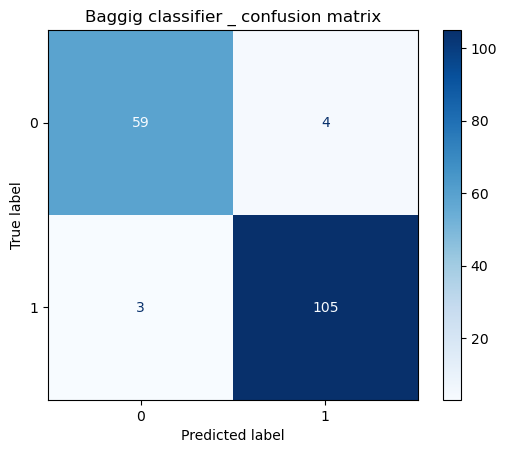

In [27]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=bagging_clf.classes_)
disp.plot(cmap = 'Blues')
plt.title('Baggig classifier _ confusion matrix')
plt.show()


In [29]:
from sklearn.metrics import roc_auc_score, roc_curve

In [31]:
auc_score = roc_auc_score(y_test, y_pred)

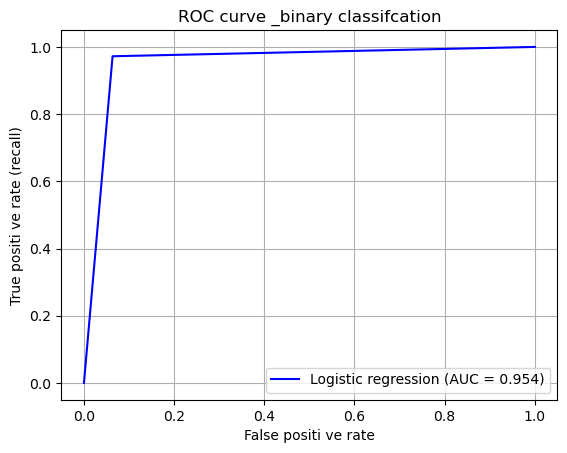

In [32]:
# compute roc values
fpr, tpr, thresholds = roc_curve(y_test, y_pred)
auc_score = roc_auc_score(y_test, y_pred)
plt.plot(fpr, tpr, label = f"Logistic regression (AUC = {auc_score:.3f})", color = "blue")
plt.xlabel("False positi ve rate")
plt.ylabel("True positi ve rate (recall)")
plt.title("ROC curve _binary classifcation")
plt.legend()
plt.grid()
plt.show()